# PHÂN TÍCH RỦI RO VỠ NỢ KHOẢN VAY TỪ BỘ DỮ LIỆU LOAN DEFAULT (CHỦ ĐỀ 10)

Bài tập nhóm học phần Khoa học dữ liệu trong kinh tế và kinh doanh, lớp học phần AEP.TOKT1138.LS(126)_01, giảng viên Trần Đức Minh.

Nhóm 2 gồm Phạm Hùng Anh (11240220), Trần Thành Lộc (11242555), Tạ Minh Quang (11240798), Nguyễn Trọng Hoàn (11248012) và Vũ Huy Anh (11246422).

Dữ liệu lấy từ [Loan Default Dataset trên Kaggle](https://www.kaggle.com/datasets/yasserh/loan-default-dataset). Mã nguồn và báo cáo lưu tại https://github.com/hunganh33333/loan-default-bai-tap-nhom-2

Notebook đi lần lượt qua 4 giai đoạn của đề bài.

1. Thu thập và đánh giá dữ liệu ban đầu
2. Tiền xử lý và làm sạch dữ liệu
3. Phân tích, kiểm định giả thuyết và trực quan hóa (kèm mô hình kiểm chứng)
4. Đánh giá tác động và khuyến nghị

> Trên Google Colab chọn Runtime, sau đó chọn Run all. Các biểu đồ được lưu vào thư mục `figures/` để đưa vào báo cáo.

In [1]:
# ===== 0. Khai báo thư viện và thiết lập chung =====
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
RANDOM_STATE = 42

# Bảng màu thống nhất cho mọi biểu đồ
BLUE, ORANGE, GRAY, INK, GRID = "#2a78d6", "#eb6834", "#898781", "#0b0b0b", "#e1e0d9"
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7", "grid.color": GRID, "axes.titlesize": 12,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "font.family": "DejaVu Sans"})

# Hàm lưu hình vào thư mục figures/ rồi hiển thị
os.makedirs("figures", exist_ok=True)
def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## GIAI ĐOẠN 1: THU THẬP VÀ ĐÁNH GIÁ DỮ LIỆU BAN ĐẦU
### 1.1. Nạp dữ liệu
Notebook thử lần lượt bốn nguồn. Đầu tiên là file `Loan_Default.csv` nằm cạnh notebook. Nếu không có, notebook tải từ Kaggle bằng `kagglehub`, thư viện này có sẵn trên Colab và bộ dữ liệu công khai nên không cần đăng nhập. Nếu vẫn không được thì lấy bản sao trong repository GitHub của nhóm, cuối cùng là một bản sao công khai khác trên GitHub.

In [2]:
# ===== 1.1. Nạp dữ liệu từ nguồn khả dụng đầu tiên =====
GROUP_REPO_RAW = ""   # (tùy chọn) link raw của file CSV nếu nhóm tải dữ liệu lên repo
PUBLIC_MIRROR = "https://raw.githubusercontent.com/MD123KHAN/Bank-Loan-Default-Prediction/main/Loan_Default.csv"

def load_data():
    # (1) File cục bộ
    for path in ["Loan_Default.csv", "data/Loan_Default.csv"]:
        if os.path.exists(path):
            print("Đọc file cục bộ:", path)
            return pd.read_csv(path)
    # (2) Kaggle qua kagglehub
    try:
        import kagglehub
        folder = kagglehub.dataset_download("yasserh/loan-default-dataset")
        path = glob.glob(os.path.join(folder, "*.csv"))[0]
        print("Đọc từ Kaggle:", path)
        return pd.read_csv(path)
    except Exception as e:
        print("Không tải được từ Kaggle:", type(e).__name__)
    # (3), (4) Bản sao trên GitHub
    for url in [GROUP_REPO_RAW, PUBLIC_MIRROR]:
        if url:
            try:
                print("Đọc từ:", url)
                return pd.read_csv(url)
            except Exception as e:
                print("Lỗi:", type(e).__name__)
    raise FileNotFoundError("Hãy tải Loan_Default.csv lên Colab (biểu tượng thư mục bên trái) rồi chạy lại.")

df = load_data()
print("Kích thước:", df.shape)
df.head()

Đọc file cục bộ: Loan_Default.csv
Kích thước: (148670, 34)


,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,loan_amount,rate_of_interest,Interest_rate_spread,Upfront_charges,term,Neg_ammortization,interest_only,lump_sum_payment,property_value,construction_type,occupancy_type,Secured_by,total_units,income,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,116500,NaN,NaN,NaN,360.0,not_neg,not_int,not_lpsm,118000.0,sb,pr,home,1U,1740.0,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,206500,NaN,NaN,NaN,360.0,not_neg,not_int,lpsm,NaN,sb,pr,home,1U,4980.0,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,406500,4.56,0.2000,595.0,360.0,neg_amm,not_int,not_lpsm,508000.0,sb,pr,home,1U,9480.0,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,456500,4.25,0.6810,NaN,360.0,not_neg,not_int,not_lpsm,658000.0,sb,pr,home,1U,11880.0,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,696500,4.00,0.3042,0.0,360.0,not_neg,not_int,not_lpsm,758000.0,sb,pr,home,1U,10440.0,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


### 1.2. Cấu trúc, kiểu dữ liệu và tỷ lệ khuyết thiếu từng trường

In [3]:
# ===== 1.2. Bảng tổng quan từng cột: kiểu dữ liệu, số giá trị khác nhau, tỷ lệ thiếu =====
overview = pd.DataFrame({
    "kieu_du_lieu": df.dtypes.astype(str),
    "so_gia_tri_khac_nhau": df.nunique(),
    "so_thieu": df.isna().sum(),
    "ty_le_thieu_%": (df.isna().mean() * 100).round(2),
    "vi_du": df.iloc[0].astype(str),
})
print("Số quan sát:", len(df), "| Số thuộc tính:", df.shape[1])
print("Số cột số:", df.select_dtypes(include="number").shape[1],
      "| Số cột phân loại:", df.select_dtypes(exclude="number").shape[1])
overview

Số quan sát: 148670 | Số thuộc tính: 34
Số cột số: 13 | Số cột phân loại: 21


,kieu_du_lieu,so_gia_tri_khac_nhau,so_thieu,ty_le_thieu_%,vi_du
ID,int64,148670,0,0.00,24890
year,int64,1,0,0.00,2019
loan_limit,str,2,3344,2.25,cf
Gender,str,4,0,0.00,Sex Not Available
approv_in_adv,str,2,908,0.61,nopre
loan_type,str,3,0,0.00,type1
loan_purpose,str,4,134,0.09,p1
Credit_Worthiness,str,2,0,0.00,l1
open_credit,str,2,0,0.00,nopc
business_or_commercial,str,2,0,0.00,nob/c


Status
0    112031
1     36639
Tỷ lệ vỡ nợ chung: 24.64%, dữ liệu mất cân bằng nhẹ (khoảng 1 khoản vỡ nợ trên 3 khoản không vỡ nợ)


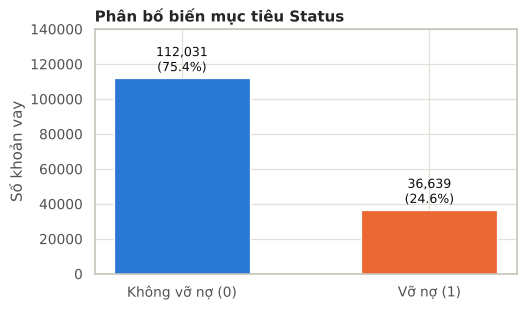

In [4]:
# ===== 1.3. Biến mục tiêu Status (1 = vỡ nợ, 0 = không vỡ nợ) =====
counts = df["Status"].value_counts().sort_index()
OVERALL = df["Status"].mean()
print(counts.to_string())
print(f"Tỷ lệ vỡ nợ chung: {OVERALL:.2%}, dữ liệu mất cân bằng nhẹ (khoảng 1 khoản vỡ nợ trên 3 khoản không vỡ nợ)")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(["Không vỡ nợ (0)", "Vỡ nợ (1)"], counts.values, color=[BLUE, ORANGE], width=0.55)
for i, v in enumerate(counts.values):
    ax.text(i, v + 1500, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom", fontsize=10, color=INK)
ax.set_ylim(0, counts.max() * 1.25)
ax.set_ylabel("Số khoản vay")
ax.set_title("Phân bố biến mục tiêu Status", loc="left", fontweight="bold")
save_fig("fig01_status")

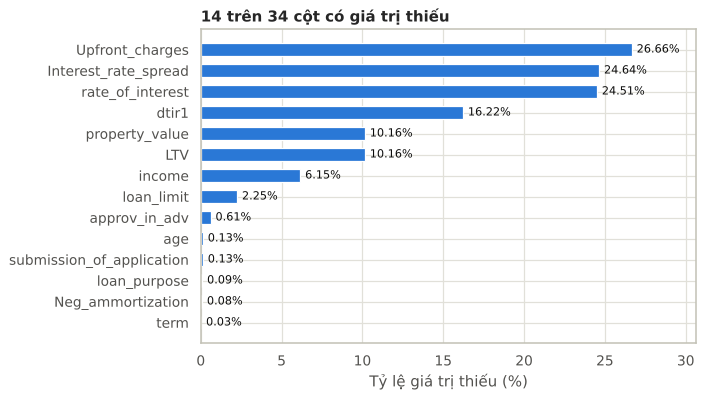

In [5]:
# ===== 1.4. Biểu đồ tỷ lệ giá trị thiếu theo cột =====
miss = (df.isna().mean() * 100).sort_values()
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(miss.index, miss.values, color=BLUE, height=0.6)
for i, v in enumerate(miss.values):
    ax.text(v + 0.3, i, f"{v:.2f}%", va="center", fontsize=9, color=INK)
ax.set_xlabel("Tỷ lệ giá trị thiếu (%)")
ax.set_xlim(0, miss.max() * 1.15)
ax.set_title(f"{len(miss)} trên {df.shape[1]} cột có giá trị thiếu", loc="left", fontweight="bold")
save_fig("fig02_missing")

In [6]:
# ===== 1.5. Kiểm tra tính nhất quán và các cột trùng thông tin =====
print("ID là duy nhất:", df["ID"].is_unique)
print("Số dòng trùng lặp hoàn toàn:", df.duplicated().sum())
print("Cột 'year' chỉ có giá trị:", df["year"].unique())

# Ba cột chỉ có 33 dòng khác giá trị phổ biến, kiểm tra xem có phải cùng 33 dòng không
a = df["construction_type"].eq("mh"); b = df["Secured_by"].eq("land"); c = df["Security_Type"].eq("Indriect")
print("construction_type='mh', Secured_by='land', Security_Type='Indriect' trùng nhau hoàn toàn:", (a == b).all() and (a == c).all(),
      f"({a.sum()} dòng, tỷ lệ vỡ nợ {df.loc[a, 'Status'].mean():.0%})")

# business_or_commercial có trùng với loan_type = type2 không?
print("business_or_commercial='b/c' trùng với loan_type='type2':",
      (df["business_or_commercial"].eq("b/c") == df["loan_type"].eq("type2")).all())

# LTV có phải là loan_amount / property_value × 100 không?
m = df["LTV"].notna()
err = (df.loc[m, "loan_amount"] / df.loc[m, "property_value"] * 100 - df.loc[m, "LTV"]).abs().max()
print(f"LTV = loan_amount / property_value × 100 (sai số lớn nhất {err:.1e})")
print("property_value thiếu đúng ở các dòng LTV thiếu:", (df["property_value"].isna() == df["LTV"].isna()).all())
print("age thiếu đúng ở các dòng submission_of_application thiếu:", (df["age"].isna() == df["submission_of_application"].isna()).all())

# Nhãn của các cột phân loại, để phát hiện nhãn không thống nhất
for col in ["Region", "Gender", "age", "Security_Type", "total_units"]:
    print(f"{col}: {sorted(df[col].dropna().unique().tolist())}")

ID là duy nhất: True
Số dòng trùng lặp hoàn toàn: 0
Cột 'year' chỉ có giá trị: [2019]
construction_type='mh', Secured_by='land', Security_Type='Indriect' trùng nhau hoàn toàn: True (33 dòng, tỷ lệ vỡ nợ 100%)
business_or_commercial='b/c' trùng với loan_type='type2': True
LTV = loan_amount / property_value × 100 (sai số lớn nhất 4.9e-08)
property_value thiếu đúng ở các dòng LTV thiếu: True
age thiếu đúng ở các dòng submission_of_application thiếu: True
Region: ['North', 'North-East', 'central', 'south']
Gender: ['Female', 'Joint', 'Male', 'Sex Not Available']
age: ['25-34', '35-44', '45-54', '55-64', '65-74', '<25', '>74']
Security_Type: ['Indriect', 'direct']
total_units: ['1U', '2U', '3U', '4U']


## GIAI ĐOẠN 2: TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU
### 2.1. Giá trị sai định dạng hoặc bất hợp lý

In [7]:
# ===== 2.1. Rà soát giá trị bất hợp lý trong các cột số =====
checks = pd.DataFrame({
    "so_dong": [
        (df["income"] == 0).sum(),
        (df["LTV"] > 100).sum(),
        (df["LTV"] > 200).sum(),
        (df["rate_of_interest"] == 0).sum(),
        (~df["term"].isin([180, 240, 300, 360]) & df["term"].notna()).sum(),
        (df["Interest_rate_spread"] < 0).sum(),
    ],
    "ty_le_vo_no": [
        df.loc[df["income"] == 0, "Status"].mean(),
        df.loc[df["LTV"] > 100, "Status"].mean(),
        df.loc[df["LTV"] > 200, "Status"].mean(),
        df.loc[df["rate_of_interest"] == 0, "Status"].mean(),
        df.loc[~df["term"].isin([180, 240, 300, 360]) & df["term"].notna(), "Status"].mean(),
        df.loc[df["Interest_rate_spread"] < 0, "Status"].mean(),
    ]},
    index=["Thu nhập = 0", "LTV > 100% (vay vượt giá trị tài sản)", "LTV > 200% (bất hợp lý)",
           "Lãi suất = 0", "Kỳ hạn lẻ (khác 15/20/25/30 năm)", "Chênh lệch lãi suất âm"])
checks["ty_le_vo_no"] = (checks["ty_le_vo_no"] * 100).round(1)
print("LTV lớn nhất:", round(df["LTV"].max(), 1), "%")
checks

LTV lớn nhất: 7831.2 %


,so_dong,ty_le_vo_no
Thu nhập = 0,1260,99.4
LTV > 100% (vay vượt giá trị tài sản),1799,65.1
LTV > 200% (bất hợp lý),17,64.7
Lãi suất = 0,1,0.0
Kỳ hạn lẻ (khác 15/20/25/30 năm),5282,22.7
Chênh lệch lãi suất âm,21883,0.0


### 2.2. So sánh tỷ lệ vỡ nợ khi thiếu và khi có dữ liệu

Nếu chỉ giữ hồ sơ đầy đủ (dropna): còn 98,187 dòng, trong đó số khoản vỡ nợ = 0
Bảng chéo: rate_of_interest thiếu × Status
Status                 0      1
rate_of_interest               
False             112031    200
True                   0  36439


,khi_thieu,khi_co,so_thieu
income,13.5,25.4,9150
loan_purpose,26.1,24.6,134
loan_limit,26.3,24.6,3344
Neg_ammortization,26.4,24.6,121
approv_in_adv,26.5,24.6,908
term,36.6,24.6,41
dtir1,67.6,16.3,24121
Upfront_charges,92.0,0.1,39642
LTV,100.0,16.1,15098
property_value,100.0,16.1,15098


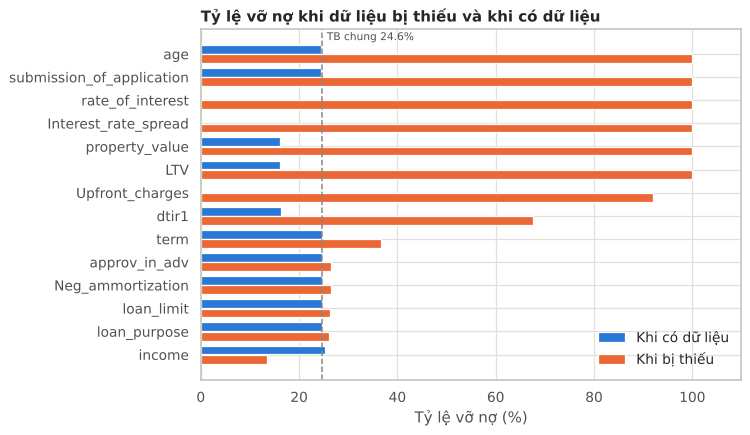

In [8]:
# ===== 2.2. Tỷ lệ vỡ nợ khi một cột bị thiếu so với khi có dữ liệu =====
miss_cols = df.columns[df.isna().any()].tolist()
mt = pd.DataFrame({
    "khi_thieu": [df.loc[df[c].isna(), "Status"].mean() * 100 for c in miss_cols],
    "khi_co": [df.loc[df[c].notna(), "Status"].mean() * 100 for c in miss_cols],
    "so_thieu": [df[c].isna().sum() for c in miss_cols]}, index=miss_cols).sort_values("khi_thieu")
display(mt.round(1))
complete = df.dropna()
print(f"Nếu chỉ giữ hồ sơ đầy đủ (dropna): còn {len(complete):,} dòng, trong đó số khoản vỡ nợ = {int(complete['Status'].sum())}")
print("Bảng chéo: rate_of_interest thiếu × Status")
print(pd.crosstab(df["rate_of_interest"].isna(), df["Status"]))

fig, ax = plt.subplots(figsize=(8.5, 5))
y = np.arange(len(mt))
ax.barh(y + 0.2, mt["khi_co"], height=0.38, color=BLUE, label="Khi có dữ liệu")
ax.barh(y - 0.2, mt["khi_thieu"], height=0.38, color=ORANGE, label="Khi bị thiếu")
ax.axvline(OVERALL * 100, color=GRAY, ls="--", lw=1.2)
ax.text(OVERALL * 100 + 1, len(mt) - 0.4, f"TB chung {OVERALL:.1%}", fontsize=8.5, color="#52514e")
ax.set_yticks(y); ax.set_yticklabels(mt.index)
ax.set_xlabel("Tỷ lệ vỡ nợ (%)"); ax.set_xlim(0, 110)
ax.legend(loc="lower right", frameon=False)
ax.set_title("Tỷ lệ vỡ nợ khi dữ liệu bị thiếu và khi có dữ liệu", loc="left", fontweight="bold")
save_fig("fig03_missing_vs_status")

### 2.3. Ngoại lệ (outliers) và độ lệch phân phối

In [9]:
# ===== 2.3. Phát hiện ngoại lệ bằng phương pháp IQR =====
num_cols = ["loan_amount", "income", "property_value", "LTV", "Upfront_charges", "dtir1", "Credit_Score", "rate_of_interest"]
rows = []
for c in num_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < lo) | (s > hi)).sum()
    rows.append([c, round(s.median(), 2), round(s.mean(), 2), round(s.skew(), 2), round(lo, 2), round(hi, 2), n_out, round(n_out / len(s) * 100, 2)])
outliers = pd.DataFrame(rows, columns=["cot", "median", "mean", "do_lech", "can_duoi", "can_tren", "so_ngoai_le", "ty_le_%"]).set_index("cot")
outliers

,median,mean,do_lech,can_duoi,can_tren,so_ngoai_le,ty_le_%
cot,,,,,,,
loan_amount,296500.00,331117.74,1.67,-163500.00,796500.00,1895,1.27
income,5760.00,6957.34,17.31,-3480.00,15720.00,6546,4.69
property_value,418000.00,497893.47,4.59,-272000.00,1168000.00,5266,3.94
LTV,75.14,72.75,120.62,21.91,124.75,1882,1.41
Upfront_charges,2596.45,3225.00,1.75,-5765.03,11159.01,2880,2.64
dtir1,39.00,37.73,-0.55,10.00,66.00,2013,1.62
Credit_Score,699.00,699.79,0.00,297.50,1101.50,0,0.00
rate_of_interest,3.99,4.05,0.39,2.50,5.50,856,0.76


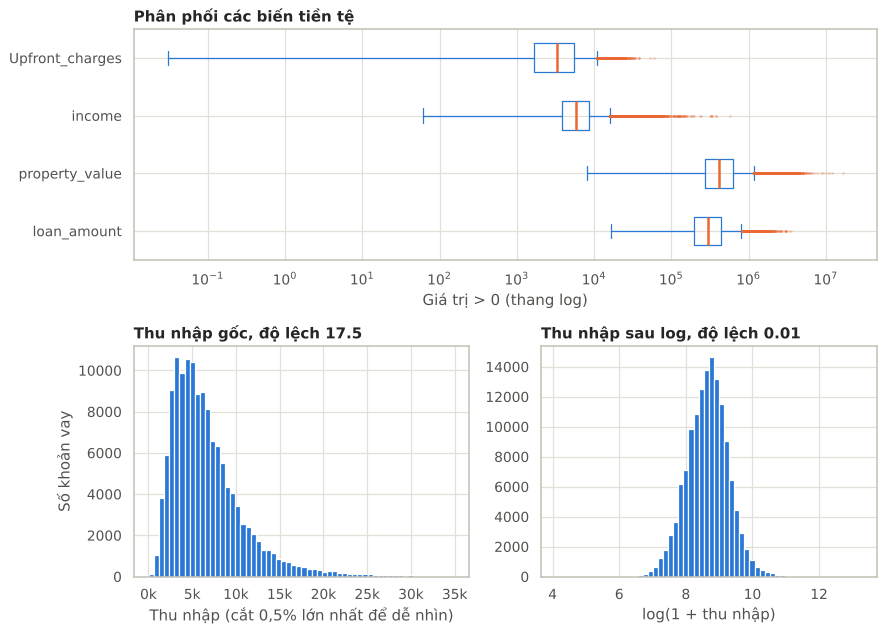

In [10]:
# ===== 2.3b. Boxplot các biến tiền tệ (trục log) và histogram thu nhập trước/sau biến đổi log =====
fig = plt.figure(figsize=(10, 7.2))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1])
axes = [fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]
money = ["loan_amount", "property_value", "income", "Upfront_charges"]
data_box = [df.loc[df[c] > 0, c] for c in money]   # bỏ giá trị 0 vì trục log không biểu diễn được 0
axes[0].boxplot(data_box, vert=False, widths=0.5,
                flierprops=dict(marker="o", markersize=2, alpha=0.3, markerfacecolor=ORANGE, markeredgecolor="none"),
                medianprops=dict(color=ORANGE, lw=2), boxprops=dict(color=BLUE), whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
axes[0].set_yticks(range(1, len(money) + 1)); axes[0].set_yticklabels(money)
axes[0].set_xscale("log"); axes[0].set_xlabel("Giá trị > 0 (thang log)")
axes[0].set_title("Phân phối các biến tiền tệ", loc="left", fontweight="bold")

inc = df.loc[df["income"] > 0, "income"]
axes[1].hist(inc[inc < inc.quantile(0.995)], bins=60, color=BLUE)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))   # hiển thị 10000 thành 10k cho gọn
axes[1].set_xlabel("Thu nhập (cắt 0,5% lớn nhất để dễ nhìn)"); axes[1].set_ylabel("Số khoản vay")
axes[1].set_title(f"Thu nhập gốc, độ lệch {inc.skew():.1f}", loc="left", fontweight="bold")
axes[2].hist(np.log1p(inc), bins=60, color=BLUE)
axes[2].set_xlabel("log(1 + thu nhập)")
axes[2].set_title(f"Thu nhập sau log, độ lệch {np.log1p(inc).skew():.2f}", loc="left", fontweight="bold")
save_fig("fig04_outliers_skew")

### 2.4. Làm sạch dữ liệu
Nhóm tạo ra hai bản dữ liệu cho hai mục đích khác nhau. Bản `df_eda` đã sửa nhãn, bỏ cột thừa và đánh dấu giá trị bất hợp lý nhưng vẫn giữ giá trị thiếu thành một nhóm riêng, bản này dùng cho phân tích ở giai đoạn 3. Bản `df_clean` điền giá trị thiếu bằng median hoặc mode và cắt ngoại lệ, dùng để minh họa dữ liệu đầu vào của mô hình. Khi huấn luyện mô hình, các bước này được làm lại trong `Pipeline` và chỉ học tham số trên tập train để không bị rò rỉ thông tin.

In [11]:
# ===== 2.4a. Sửa định dạng, bỏ cột thừa, đánh dấu giá trị bất hợp lý, kết quả là df_eda =====
df_eda = df.copy()

# Bỏ cột không mang thông tin: ID là mã định danh, year chỉ có một giá trị (2019)
df_eda = df_eda.drop(columns=["ID", "year"])

# Bỏ cột trùng thông tin: Secured_by và Security_Type trùng hoàn toàn với construction_type;
# business_or_commercial trùng hoàn toàn với loan_type = 'type2'
df_eda = df_eda.drop(columns=["Secured_by", "Security_Type", "business_or_commercial"])

# Chuẩn hóa nhãn viết hoa/thường không thống nhất và nhãn mang nghĩa "thiếu"
df_eda["Region"] = df_eda["Region"].replace({"south": "South", "central": "Central"})
df_eda["Gender"] = df_eda["Gender"].replace({"Sex Not Available": "Không rõ"})

# Thu nhập bằng 0 là bất hợp lý với người đi vay thế chấp nên coi là thiếu và gắn cờ
df_eda["income_zero_flag"] = (df_eda["income"] == 0).astype(int)
df_eda.loc[df_eda["income"] == 0, "income"] = np.nan

# Thứ tự nhóm tuổi (dùng cho biểu đồ và mã hóa thứ bậc)
AGE_ORDER = ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74"]
print("Kích thước df_eda:", df_eda.shape)

Kích thước df_eda: (148670, 30)


In [12]:
# ===== 2.4b. Điền giá trị thiếu và cắt ngoại lệ, kết quả là df_clean =====
df_clean = df_eda.copy()
numeric = ["loan_amount", "rate_of_interest", "Interest_rate_spread", "Upfront_charges", "term",
           "property_value", "income", "Credit_Score", "LTV", "dtir1"]
categorical = [c for c in df_clean.columns if c not in numeric + ["Status", "income_zero_flag"]]

# (1) Cờ đánh dấu giá trị thiếu, giữ lại thông tin "bị thiếu" vì nó gắn với vỡ nợ (mục 2.2)
for c in numeric:
    if df_clean[c].isna().any():
        df_clean[f"{c}_missing"] = df_clean[c].isna().astype(int)

# (2) Cắt ngoại lệ (winsorize) tại phân vị 1% và 99% thay vì xóa dòng
clip_cols = ["loan_amount", "income", "property_value", "LTV", "Upfront_charges"]
for c in clip_cols:
    lo, hi = df_clean[c].quantile([0.01, 0.99])
    n = ((df_clean[c] < lo) | (df_clean[c] > hi)).sum()
    df_clean[c] = df_clean[c].clip(lo, hi)
    print(f"Cắt {c}: {n:,} giá trị về khoảng [{lo:,.1f}; {hi:,.1f}]")

# (3) Điền median cho biến số (phân phối lệch, có ngoại lệ) và mode cho biến phân loại
for c in numeric:
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())
for c in categorical:
    df_clean[c] = df_clean[c].fillna(df_clean[c].mode()[0])

print("Số giá trị thiếu còn lại:", int(df_clean.isna().sum().sum()), "| Kích thước df_clean:", df_clean.shape)

Cắt loan_amount: 2,643 giá trị về khoảng [66,500.0; 856,500.0]
Cắt income: 2,570 giá trị về khoảng [1,260.0; 26,844.6]
Cắt property_value: 2,217 giá trị về khoảng [88,000.0; 1,808,000.0]
Cắt LTV: 2,666 giá trị về khoảng [19.6; 102.8]
Cắt Upfront_charges: 1,091 giá trị về khoảng [0.0; 14,297.0]
Số giá trị thiếu còn lại: 0 | Kích thước df_clean: (148670, 38)


In [13]:
# ===== 2.4c. Minh chứng: vì sao KHÔNG dùng dữ liệu đã điền median để phân tích tỷ lệ vỡ nợ =====
bins_ltv = [0, 60, 80, 90, 100, np.inf]
before = df_eda.groupby(pd.cut(df_eda["LTV"], bins_ltv), observed=True)["Status"].mean() * 100
after = df_clean.groupby(pd.cut(df_clean["LTV"], bins_ltv), observed=True)["Status"].mean() * 100
compare = pd.DataFrame({"truoc_khi_dien_%": before.round(1), "sau_khi_dien_median_%": after.round(1)})
print(f"Median LTV = {df_eda['LTV'].median():.2f}, nên toàn bộ {df_eda['LTV'].isna().sum():,} khoản thiếu LTV (100% vỡ nợ) bị dồn vào nhóm 60 đến 80%")
compare

Median LTV = 75.14, nên toàn bộ 15,098 khoản thiếu LTV (100% vỡ nợ) bị dồn vào nhóm 60 đến 80%


,truoc_khi_dien_%,sau_khi_dien_median_%
LTV,,
"(0.0, 60.0]",13.9,13.9
"(60.0, 80.0]",12.9,33.2
"(80.0, 90.0]",18.4,18.4
"(90.0, 100.0]",19.7,19.7
"(100.0, inf]",65.1,65.1


In [14]:
# ===== 2.5. Mã hóa biến phân loại và chuẩn hóa thang đo (minh họa trên df_clean) =====
enc = df_clean.copy()

# (1) Biến 2 mức mã hóa thành 0/1
binary_cols = [c for c in categorical if enc[c].nunique() == 2]
for c in binary_cols:
    first = sorted(enc[c].unique())[0]
    enc[c] = (enc[c] != first).astype(int)

# (2) Biến có thứ bậc dùng mã hóa thứ tự (Ordinal)
enc["age"] = enc["age"].map({a: i for i, a in enumerate(AGE_ORDER)})
enc["total_units"] = enc["total_units"].str.replace("U", "").astype(int)

# (3) Biến danh nghĩa nhiều mức dùng One Hot, bỏ cột đầu để tránh đa cộng tuyến
nominal = [c for c in categorical if c not in binary_cols + ["age", "total_units"]]
enc = pd.get_dummies(enc, columns=nominal, drop_first=True, dtype=int)

# (4) Biến tiền tệ lệch phải lấy log(1+x), sau đó dùng RobustScaler (median và IQR) cho mọi biến số
skewed = ["loan_amount", "income", "property_value"]   # Upfront_charges có nhiều số 0, lấy log làm lệch trái hơn nên không log
skew_before = enc[skewed].skew().round(2)
enc[skewed] = np.log1p(enc[skewed])
enc[numeric] = RobustScaler().fit_transform(enc[numeric])
print("Biến 2 mức:", binary_cols)
print("Biến One Hot:", nominal)
print(pd.DataFrame({"do_lech_sau_cat_ngoai_le": skew_before, "do_lech_sau_log": enc[skewed].skew().round(2)}))
print("Kích thước sau mã hóa:", enc.shape)

Biến 2 mức: ['loan_limit', 'approv_in_adv', 'Credit_Worthiness', 'open_credit', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'construction_type', 'co-applicant_credit_type', 'submission_of_application']
Biến One Hot: ['Gender', 'loan_type', 'loan_purpose', 'occupancy_type', 'credit_type', 'Region']
                do_lech_sau_cat_ngoai_le  do_lech_sau_log
loan_amount                         0.75            -0.40
income                              1.96            -0.03
property_value                      1.83            -0.10
Kích thước sau mã hóa: (148670, 48)


## GIAI ĐOẠN 3: PHÂN TÍCH, KIỂM ĐỊNH GIẢ THUYẾT VÀ TRỰC QUAN HÓA

| Mã | Giả thuyết ban đầu |
|---|---|
| H1 | Điểm tín dụng (Credit_Score) càng thấp thì tỷ lệ vỡ nợ càng cao |
| H2 | Tỷ lệ cho vay trên giá trị tài sản (LTV) càng cao thì càng dễ vỡ nợ |
| H3 | Tỷ lệ nợ trên thu nhập (dtir1) càng cao thì càng dễ vỡ nợ |
| H4 | Người vay thu nhập thấp có tỷ lệ vỡ nợ cao hơn |
| H5 | Tỷ lệ vỡ nợ khác nhau giữa các nhóm tuổi |
| H6 | Khoản vay có cấu trúc rủi ro (trả gốc âm, trả gộp cuối kỳ, chỉ trả lãi, vay kinh doanh) vỡ nợ nhiều hơn |
| H7 | Tỷ lệ vỡ nợ khác nhau theo đơn vị chấm điểm tín dụng (credit_type) |

Với biến phân loại hoặc biến số đã chia nhóm, nhóm dùng kiểm định Chi bình phương và đo độ mạnh bằng Cramér's V. Với biến số, nhóm so sánh hai nhóm Status bằng kiểm định Mann Whitney U. Mức ý nghĩa là 5%.

In [15]:
# ===== 3.0. Hàm dùng chung: bảng tỷ lệ vỡ nợ, kiểm định Chi bình phương, vẽ biểu đồ =====
results = []   # lưu kết quả kiểm định để tổng hợp cuối giai đoạn

def rate_table(data, col, order=None):
    # Tỷ lệ vỡ nợ và số khoản vay theo từng nhóm; nhóm thiếu dữ liệu đặt tên riêng
    s = data[col].astype(object).where(data[col].notna(), "Thiếu dữ liệu").astype(str)
    t = data.groupby(s, observed=True)["Status"].agg(so_khoan_vay="size", ty_le_vo_no="mean")
    if order is not None:
        order = [str(o) for o in order]
        t = t.reindex([o for o in order if o in t.index] + [i for i in t.index if i not in order])
    return t

def chi2_test(data, col, label, hypothesis):
    # Kiểm định độc lập Chi bình phương giữa nhóm và Status, kèm Cramér's V
    ct = pd.crosstab(data[col].astype(str), data["Status"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    results.append({"gia_thuyet": hypothesis, "bien": label, "kiem_dinh": "Chi bình phương",
                    "thong_ke": round(chi2, 1), "p_value": p, "cramer_v": round(v, 3)})
    print(f"{label}: Chi2 = {chi2:,.1f}, df = {dof}, p = {p:.3g}, Cramér's V = {v:.3f}")

def plot_rate(t, title, xlabel, fname, rotate=0):
    # Biểu đồ cột tỷ lệ vỡ nợ theo nhóm; nhóm "Thiếu dữ liệu" tô màu cam để tách biệt
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    colors = [ORANGE if i == "Thiếu dữ liệu" else BLUE for i in t.index]
    ax.bar(t.index, t["ty_le_vo_no"] * 100, color=colors, width=0.6)
    ax.axhline(OVERALL * 100, color=GRAY, ls="--", lw=1.2, label=f"Trung bình chung {OVERALL:.1%}")
    for i, (r, n) in enumerate(zip(t["ty_le_vo_no"], t["so_khoan_vay"])):
        ax.text(i, r * 100 + 1, f"{r:.1%}\nn={n:,}", ha="center", va="bottom", fontsize=8.5, color=INK,
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_ylim(0, t["ty_le_vo_no"].max() * 100 * 1.3)
    ax.set_ylabel("Tỷ lệ vỡ nợ (%)"); ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.legend(loc="upper left", frameon=False)
    plt.xticks(rotation=rotate)
    save_fig(fname)

Nhóm điểm tín dụng: Chi2 = 9.5, df = 3, p = 0.0238, Cramér's V = 0.008
Mann Whitney U: p = 0.124 | Median điểm: vỡ nợ = 700, không vỡ nợ = 699


,so_khoan_vay,ty_le_vo_no
cs_bin,,
500 đến 600,37546,0.246178
601 đến 700,37247,0.245013
701 đến 800,36753,0.242592
801 đến 900,37124,0.251966


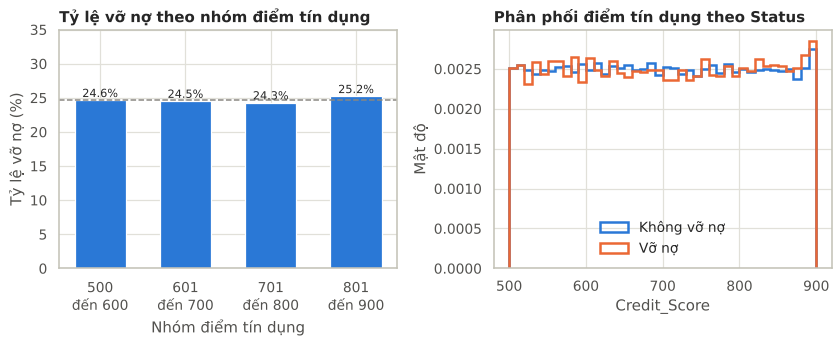

In [16]:
# ===== H1. Điểm tín dụng và vỡ nợ =====
cs_bin = pd.cut(df_eda["Credit_Score"], [499, 600, 700, 800, 900], labels=["500 đến 600", "601 đến 700", "701 đến 800", "801 đến 900"])
tmp = df_eda.assign(cs_bin=cs_bin)
t = rate_table(tmp, "cs_bin", ["500 đến 600", "601 đến 700", "701 đến 800", "801 đến 900"])
display(t)
chi2_test(tmp, "cs_bin", "Nhóm điểm tín dụng", "H1")
u, p = stats.mannwhitneyu(df_eda.loc[df_eda.Status == 1, "Credit_Score"], df_eda.loc[df_eda.Status == 0, "Credit_Score"])
print(f"Mann Whitney U: p = {p:.3f} | Median điểm: vỡ nợ = {df_eda.loc[df_eda.Status == 1, 'Credit_Score'].median():.0f}, "
      f"không vỡ nợ = {df_eda.loc[df_eda.Status == 0, 'Credit_Score'].median():.0f}")
results.append({"gia_thuyet": "H1", "bien": "Credit_Score", "kiem_dinh": "Mann Whitney U", "thong_ke": round(u, 0), "p_value": p, "cramer_v": np.nan})

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
axes[0].bar([i.replace(" đến ", "\nđến ") for i in t.index], t["ty_le_vo_no"] * 100, color=BLUE, width=0.6)   # xuống dòng cho nhãn đỡ chồng nhau
axes[0].axhline(OVERALL * 100, color=GRAY, ls="--", lw=1.2)
for i, r in enumerate(t["ty_le_vo_no"]):
    axes[0].text(i, r * 100 + 0.5, f"{r:.1%}", ha="center", fontsize=9)
axes[0].set_ylim(0, 35); axes[0].set_ylabel("Tỷ lệ vỡ nợ (%)"); axes[0].set_xlabel("Nhóm điểm tín dụng")
axes[0].set_title("Tỷ lệ vỡ nợ theo nhóm điểm tín dụng", loc="left", fontweight="bold")
for s_val, col, lab in [(0, BLUE, "Không vỡ nợ"), (1, ORANGE, "Vỡ nợ")]:
    axes[1].hist(df_eda.loc[df_eda.Status == s_val, "Credit_Score"], bins=40, density=True, histtype="step", lw=2, color=col, label=lab)
axes[1].set_xlabel("Credit_Score"); axes[1].set_ylabel("Mật độ")
axes[1].legend(frameon=False, loc="lower center")
axes[1].set_title("Phân phối điểm tín dụng theo Status", loc="left", fontweight="bold")
save_fig("fig05_H1_credit_score")

Nhóm LTV (bỏ dòng thiếu): Chi2 = 4,000.8, df = 4, p = 0, Cramér's V = 0.173
Spearman giữa LTV và Status (bỏ dòng thiếu): rho = 0.090, p = 6.6e-239


,so_khoan_vay,ty_le_vo_no
ltv_bin,,
≤60%,32565,0.139229
60 đến 80%,49895,0.129392
80 đến 90%,26153,0.184377
90 đến 100%,23160,0.196891
>100%,1799,0.650917
Thiếu dữ liệu,15098,0.999868


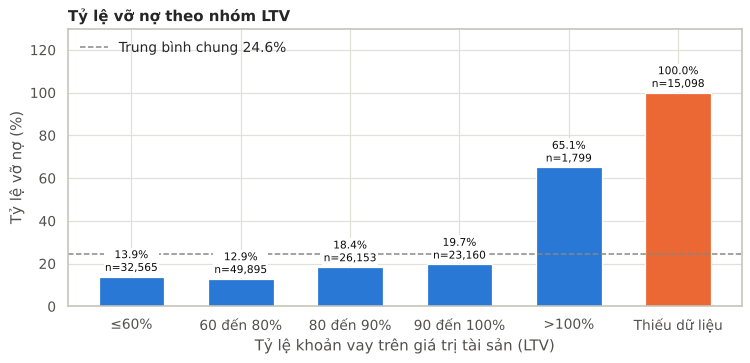

In [17]:
# ===== H2. LTV và vỡ nợ =====
ltv_labels = ["≤60%", "60 đến 80%", "80 đến 90%", "90 đến 100%", ">100%"]
tmp = df_eda.assign(ltv_bin=pd.cut(df_eda["LTV"], [0, 60, 80, 90, 100, np.inf], labels=ltv_labels))
t = rate_table(tmp, "ltv_bin", ltv_labels)
display(t)
chi2_test(tmp.dropna(subset=["LTV"]), "ltv_bin", "Nhóm LTV (bỏ dòng thiếu)", "H2")
rho, p = stats.spearmanr(df_eda["LTV"], df_eda["Status"], nan_policy="omit")
print(f"Spearman giữa LTV và Status (bỏ dòng thiếu): rho = {rho:.3f}, p = {p:.3g}")
plot_rate(t, "Tỷ lệ vỡ nợ theo nhóm LTV", "Tỷ lệ khoản vay trên giá trị tài sản (LTV)", "fig06_H2_ltv")

Nhóm DTI (bỏ dòng thiếu): Chi2 = 5,014.0, df = 4, p = 0, Cramér's V = 0.201


,so_khoan_vay,ty_le_vo_no
dti_bin,,
≤30%,27970,0.156024
30 đến 36%,21313,0.119505
36 đến 43%,35857,0.129905
43 đến 50%,30770,0.164706
>50%,8639,0.427364
Thiếu dữ liệu,24121,0.676174


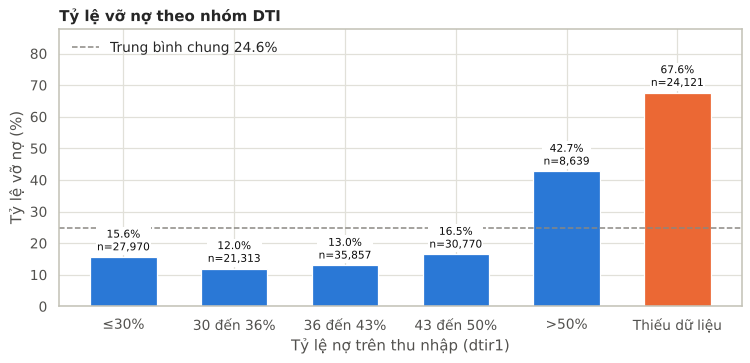

In [18]:
# ===== H3. Tỷ lệ nợ trên thu nhập (DTI) và vỡ nợ =====
dti_labels = ["≤30%", "30 đến 36%", "36 đến 43%", "43 đến 50%", ">50%"]
tmp = df_eda.assign(dti_bin=pd.cut(df_eda["dtir1"], [0, 30, 36, 43, 50, 100], labels=dti_labels))
t = rate_table(tmp, "dti_bin", dti_labels)
display(t)
chi2_test(tmp.dropna(subset=["dtir1"]), "dti_bin", "Nhóm DTI (bỏ dòng thiếu)", "H3")
plot_rate(t, "Tỷ lệ vỡ nợ theo nhóm DTI", "Tỷ lệ nợ trên thu nhập (dtir1)", "fig07_H3_dti")

Ranh giới các nhóm thu nhập: [Interval(59.999, 3420.0, closed='right'), Interval(3420.0, 4980.0, closed='right'), Interval(4980.0, 6720.0, closed='right'), Interval(6720.0, 9420.0, closed='right'), Interval(9420.0, 578580.0, closed='right')]
Nhóm thu nhập (bỏ dòng thiếu): Chi2 = 2,075.6, df = 4, p = 0, Cramér's V = 0.123
Mann Whitney U thu nhập: p = 0 | median vỡ nợ = 5,040, không vỡ nợ = 6,000
Riêng nhóm thu nhập = 0: 1,260 khoản, tỷ lệ vỡ nợ 99.4%


,so_khoan_vay,ty_le_vo_no
inc_q,,
Q1 (thấp nhất),28547,0.342313
Q2,27829,0.259154
Q3,26988,0.223803
Q4,27620,0.202064
Q5 (cao nhất),27276,0.203219
Thiếu dữ liệu,10410,0.239289


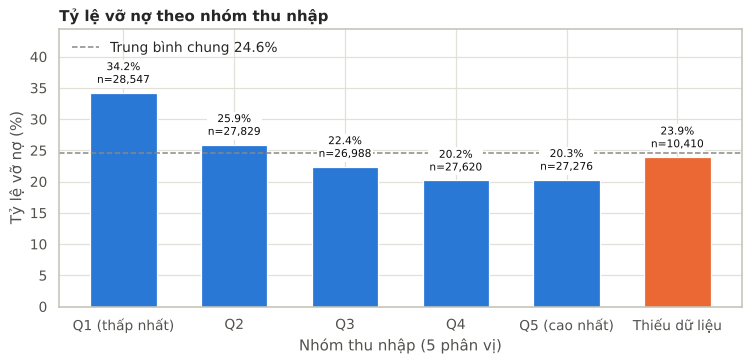

In [19]:
# ===== H4. Thu nhập và vỡ nợ (chia 5 nhóm bằng nhau theo phân vị) =====
inc_labels = ["Q1 (thấp nhất)", "Q2", "Q3", "Q4", "Q5 (cao nhất)"]
tmp = df_eda.assign(inc_q=pd.qcut(df_eda["income"], 5, labels=inc_labels))
print("Ranh giới các nhóm thu nhập:", pd.qcut(df_eda["income"], 5).cat.categories.tolist())
t = rate_table(tmp, "inc_q", inc_labels)
display(t)
chi2_test(tmp.dropna(subset=["income"]), "inc_q", "Nhóm thu nhập (bỏ dòng thiếu)", "H4")
u, p = stats.mannwhitneyu(df_eda.loc[df_eda.Status == 1, "income"].dropna(), df_eda.loc[df_eda.Status == 0, "income"].dropna())
print(f"Mann Whitney U thu nhập: p = {p:.3g} | median vỡ nợ = {df_eda.loc[df_eda.Status == 1, 'income'].median():,.0f}, "
      f"không vỡ nợ = {df_eda.loc[df_eda.Status == 0, 'income'].median():,.0f}")
print(f"Riêng nhóm thu nhập = 0: {df['income'].eq(0).sum():,} khoản, tỷ lệ vỡ nợ {df.loc[df.income == 0, 'Status'].mean():.1%}")
plot_rate(t, "Tỷ lệ vỡ nợ theo nhóm thu nhập", "Nhóm thu nhập (5 phân vị)", "fig08_H4_income")

Nhóm tuổi (bỏ dòng thiếu): Chi2 = 374.5, df = 6, p = 8.44e-78, Cramér's V = 0.050


,so_khoan_vay,ty_le_vo_no
age,,
<25,1337,0.289454
25-34,19142,0.221920
35-44,32818,0.222713
45-54,34720,0.240467
55-64,32534,0.258868
65-74,20744,0.268560
>74,7175,0.300070
Thiếu dữ liệu,200,1.000000


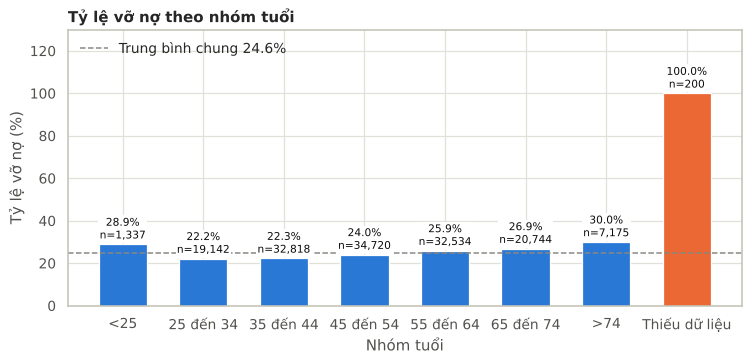

In [20]:
# ===== H5. Nhóm tuổi và vỡ nợ =====
AGE_VN = {"<25": "<25", "25-34": "25 đến 34", "35-44": "35 đến 44", "45-54": "45 đến 54",
          "55-64": "55 đến 64", "65-74": "65 đến 74", ">74": ">74"}   # nhãn hiển thị trên biểu đồ
t = rate_table(df_eda, "age", AGE_ORDER)
display(t)
t_vn = t.rename(index=AGE_VN)
chi2_test(df_eda.dropna(subset=["age"]), "age", "Nhóm tuổi (bỏ dòng thiếu)", "H5")
plot_rate(t_vn, "Tỷ lệ vỡ nợ theo nhóm tuổi", "Nhóm tuổi", "fig09_H5_age")

Trả gốc âm: Chi2 = 3,610.2, df = 1, p = 0, Cramér's V = 0.156
Trả gộp cuối kỳ: Chi2 = 5,237.8, df = 1, p = 0, Cramér's V = 0.188
Chỉ trả lãi: Chi2 = 28.5, df = 1, p = 9.4e-08, Cramér's V = 0.014
Vay kinh doanh (type2): Chi2 = 1,272.8, df = 1, p = 9.17e-279, Cramér's V = 0.093
Vượt hạn mức chuẩn (ncf): Chi2 = 427.4, df = 1, p = 5.99e-95, Cramér's V = 0.054
Mức tín nhiệm l2: Chi2 = 180.4, df = 1, p = 3.92e-41, Cramér's V = 0.035


,co_%,khong_%,so_khoan_co
dac_diem,,,
Chỉ trả lãi,27.3,24.5,7110
Mức tín nhiệm l2,31.8,24.3,6326
Vượt hạn mức chuẩn (ncf),33.2,24.0,9978
Vay kinh doanh (type2),34.5,23.0,20762
Trả gốc âm,44.6,22.4,15129
Trả gộp cuối kỳ,77.7,23.4,3384


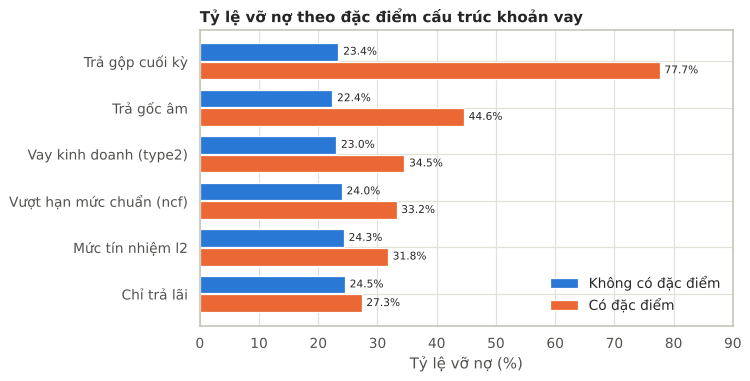

In [21]:
# ===== H6. Đặc điểm cấu trúc khoản vay =====
features = {
    "Neg_ammortization": ("neg_amm", "Trả gốc âm"),
    "lump_sum_payment": ("lpsm", "Trả gộp cuối kỳ"),
    "interest_only": ("int_only", "Chỉ trả lãi"),
    "loan_type": ("type2", "Vay kinh doanh (type2)"),
    "loan_limit": ("ncf", "Vượt hạn mức chuẩn (ncf)"),
    "Credit_Worthiness": ("l2", "Mức tín nhiệm l2"),
}
rows = []
for col, (yes, label) in features.items():
    sub = df_eda.dropna(subset=[col])
    flag = sub[col].eq(yes)
    rows.append([label, sub.loc[flag, "Status"].mean() * 100, sub.loc[~flag, "Status"].mean() * 100, flag.sum()])
    chi2_test(sub.assign(flag=flag), "flag", label, "H6")
f6 = pd.DataFrame(rows, columns=["dac_diem", "co_%", "khong_%", "so_khoan_co"]).set_index("dac_diem").sort_values("co_%")
display(f6.round(1))

fig, ax = plt.subplots(figsize=(8.5, 4.4))
y = np.arange(len(f6))
ax.barh(y + 0.2, f6["khong_%"], height=0.38, color=BLUE, label="Không có đặc điểm")
ax.barh(y - 0.2, f6["co_%"], height=0.38, color=ORANGE, label="Có đặc điểm")
for i, (a, b) in enumerate(zip(f6["co_%"], f6["khong_%"])):
    ax.text(a + 0.8, i - 0.2, f"{a:.1f}%", va="center", fontsize=8.5)
    ax.text(b + 0.8, i + 0.2, f"{b:.1f}%", va="center", fontsize=8.5)
ax.set_yticks(y); ax.set_yticklabels(f6.index)
ax.set_xlim(0, 90); ax.set_xlabel("Tỷ lệ vỡ nợ (%)")
ax.legend(loc="lower right", frameon=False)
ax.set_title("Tỷ lệ vỡ nợ theo đặc điểm cấu trúc khoản vay", loc="left", fontweight="bold")
save_fig("fig10_H6_loan_features")

credit_type: Chi2 = 52,135.3, df = 3, p = 0, Cramér's V = 0.592
Trong nhóm EQUI, tỷ lệ thiếu rate_of_interest: 98.7%
co-applicant_credit_type: Chi2 = 3,092.4, df = 1, p = 0, Cramér's V = 0.144


,so_khoan_vay,ty_le_vo_no
credit_type,,
CIB,48152,0.158041
CRIF,43901,0.162343
EXP,41319,0.159854
EQUI,15298,0.999935


,so_khoan_vay,ty_le_vo_no
co-applicant_credit_type,,
CIB,74392,0.184334
EXP,74278,0.308651


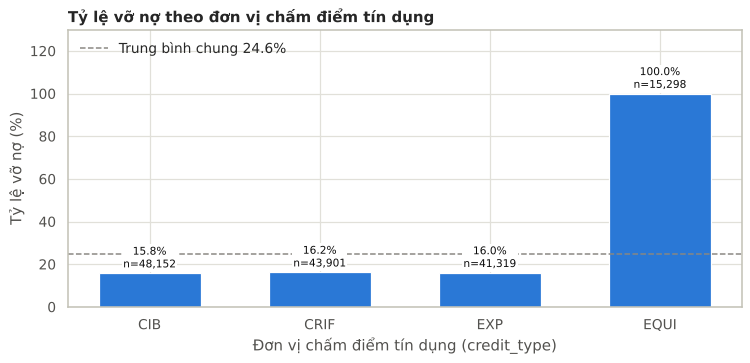

In [22]:
# ===== H7. Đơn vị chấm điểm tín dụng (credit_type) =====
t = rate_table(df_eda, "credit_type", ["CIB", "CRIF", "EXP", "EQUI"])
display(t)
chi2_test(df_eda, "credit_type", "credit_type", "H7")
print("Trong nhóm EQUI, tỷ lệ thiếu rate_of_interest:", f"{df_eda.loc[df_eda.credit_type == 'EQUI', 'rate_of_interest'].isna().mean():.1%}")
t2 = rate_table(df_eda, "co-applicant_credit_type")
display(t2)
chi2_test(df_eda, "co-applicant_credit_type", "co-applicant_credit_type", "H7")
plot_rate(t, "Tỷ lệ vỡ nợ theo đơn vị chấm điểm tín dụng", "Đơn vị chấm điểm tín dụng (credit_type)", "fig11_H7_credit_type")

Nhóm LTV,≤60%,60 đến 80%,80 đến 90%,90 đến 100%,>100%
Nhóm DTI,,,,,
≤30%,12.9,12.4,19.4,25.9,82.1
30 đến 36%,9.6,8.7,14.3,18.8,66.1
36 đến 43%,11.0,10.0,15.4,17.2,67.7
43 đến 50%,14.3,13.9,18.7,19.5,65.6
>50%,61.5,52.3,35.5,31.6,57.8


Nhóm LTV,≤60%,60 đến 80%,80 đến 90%,90 đến 100%,>100%
Nhóm DTI,,,,,
≤30%,9225,11337,4314,2859,234
30 đến 36%,5615,8750,3799,2916,233
36 đến 43%,8615,14642,6616,5605,378
43 đến 50%,7473,11552,6077,5354,314
>50%,1201,1983,2569,2540,346


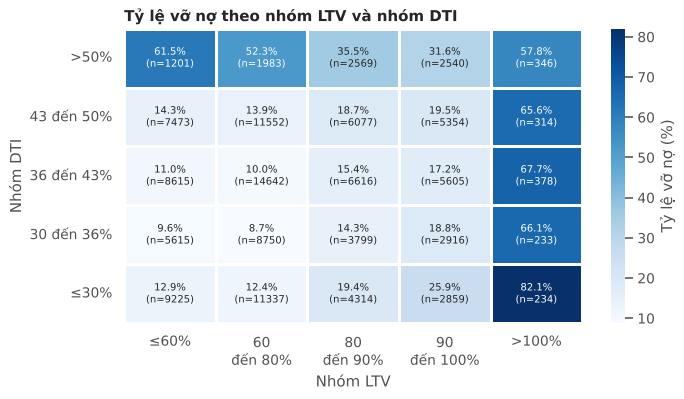

In [23]:
# ===== 3.8. Heatmap tỷ lệ vỡ nợ theo hai chiều LTV × DTI =====
tmp = df_eda.dropna(subset=["LTV", "dtir1"]).copy()
tmp["Nhóm LTV"] = pd.cut(tmp["LTV"], [0, 60, 80, 90, 100, np.inf], labels=ltv_labels)
tmp["Nhóm DTI"] = pd.cut(tmp["dtir1"], [0, 30, 36, 43, 50, 100], labels=dti_labels)
grid = tmp.pivot_table(index="Nhóm DTI", columns="Nhóm LTV", values="Status", aggfunc="mean", observed=True) * 100
cnt = tmp.pivot_table(index="Nhóm DTI", columns="Nhóm LTV", values="Status", aggfunc="size", observed=True)
display(grid.round(1)); display(cnt)

fig, ax = plt.subplots(figsize=(8, 4.6))
annot = grid.round(1).astype(str) + "%\n(n=" + cnt.astype(str) + ")"
sns.heatmap(grid, annot=annot, fmt="", cmap="Blues", cbar_kws={"label": "Tỷ lệ vỡ nợ (%)"}, linewidths=2, linecolor="white", ax=ax, annot_kws={"fontsize": 8})
ax.invert_yaxis()
ax.set_xticklabels([l.get_text().replace(" đến ", "\nđến ") for l in ax.get_xticklabels()], rotation=0)
ax.set_title("Tỷ lệ vỡ nợ theo nhóm LTV và nhóm DTI", loc="left", fontweight="bold")
save_fig("fig12_heatmap_ltv_dti")

income             -0.116
property_value     -0.108
loan_amount        -0.069
Upfront_charges    -0.023
term               -0.017
Credit_Score        0.004
rate_of_interest    0.023
LTV                 0.090
dtir1               0.096
Status              1.000


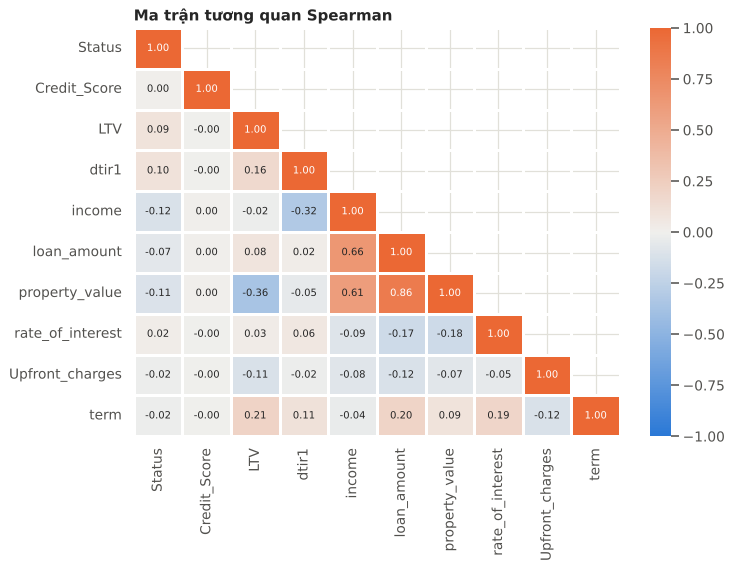

In [24]:
# ===== 3.9. Ma trận tương quan Spearman giữa các biến số và Status =====
corr_cols = ["Status", "Credit_Score", "LTV", "dtir1", "income", "loan_amount", "property_value",
             "rate_of_interest", "Upfront_charges", "term"]
# Bỏ Interest_rate_spread: cột này chỉ có giá trị ở các khoản không vỡ nợ (Status luôn = 0) nên không tính được tương quan
corr = df_eda[corr_cols].corr(method="spearman")
print(corr["Status"].round(3).sort_values().to_string())
fig, ax = plt.subplots(figsize=(8.5, 6.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=sns.blend_palette([BLUE, "#f0efec", ORANGE], as_cmap=True),
            vmin=-1, vmax=1, linewidths=1, linecolor="white", annot_kws={"fontsize": 8}, ax=ax)
ax.set_title("Ma trận tương quan Spearman", loc="left", fontweight="bold")
save_fig("fig13_corr_heatmap")

In [25]:
# ===== 3.10. Tổng hợp kết quả kiểm định giả thuyết =====
res = pd.DataFrame(results)
res["p_value"] = res["p_value"].map(lambda p: "< 0,001" if p < 0.001 else f"{p:.3f}")
res["thong_ke"] = res["thong_ke"].map(lambda v: f"{v:,.1f}")
res

,gia_thuyet,bien,kiem_dinh,thong_ke,p_value,cramer_v
0,H1,Nhóm điểm tín dụng,Chi bình phương,9.5,0.024,0.008
1,H1,Credit_Score,Mann Whitney U,"2,063,311,078.0",0.124,NaN
2,H2,Nhóm LTV (bỏ dòng thiếu),Chi bình phương,"4,000.8","< 0,001",0.173
3,H3,Nhóm DTI (bỏ dòng thiếu),Chi bình phương,"5,014.0","< 0,001",0.201
4,H4,Nhóm thu nhập (bỏ dòng thiếu),Chi bình phương,"2,075.6","< 0,001",0.123
5,H5,Nhóm tuổi (bỏ dòng thiếu),Chi bình phương,374.5,"< 0,001",0.050
6,H6,Trả gốc âm,Chi bình phương,"3,610.2","< 0,001",0.156
7,H6,Trả gộp cuối kỳ,Chi bình phương,"5,237.8","< 0,001",0.188
8,H6,Chỉ trả lãi,Chi bình phương,28.5,"< 0,001",0.014
9,H6,Vay kinh doanh (type2),Chi bình phương,"1,272.8","< 0,001",0.093


### 3.11. Kiểm chứng bằng mô hình học máy và phát hiện rò rỉ dữ liệu (data leakage)
Nhóm thử hai kịch bản. Kịch bản A dùng toàn bộ thuộc tính. Kịch bản B bỏ các thuộc tính mà việc thiếu dữ liệu gần như quyết định Status, gồm rate_of_interest, Interest_rate_spread, Upfront_charges, property_value, LTV, dtir1, credit_type, age, submission_of_application và construction_type.

Các bước tiền xử lý gồm điền median hoặc mode, tạo cờ thiếu, lấy log, RobustScaler và One Hot đều nằm trong `Pipeline` và chỉ học trên tập train chiếm 70% dữ liệu, có chia phân tầng theo Status.

In [26]:
# ===== 3.11a. Chuẩn bị dữ liệu, hàm huấn luyện và đánh giá =====
y_all = df_eda["Status"]
X_all = df_eda.drop(columns=["Status"])
NUM_ALL = ["loan_amount", "rate_of_interest", "Interest_rate_spread", "Upfront_charges", "term",
           "property_value", "income", "Credit_Score", "LTV", "dtir1", "income_zero_flag"]
CAT_ALL = [c for c in X_all.columns if c not in NUM_ALL]
LEAK = ["rate_of_interest", "Interest_rate_spread", "Upfront_charges", "property_value", "LTV", "dtir1",
        "credit_type", "age", "submission_of_application", "construction_type"]
SKEWED = ["loan_amount", "income", "property_value"]

def build_pipeline(num, cat, model):
    skew = [c for c in num if c in SKEWED]
    other = [c for c in num if c not in SKEWED]
    pre = ColumnTransformer([
        ("skew", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                           ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("sc", RobustScaler())]), skew),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", RobustScaler())]), other),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))]), cat)])
    return Pipeline([("pre", pre), ("model", model)])

def evaluate(name, num, cat):
    X_tr, X_te, y_tr, y_te = train_test_split(X_all[num + cat], y_all, test_size=0.3, stratify=y_all, random_state=RANDOM_STATE)
    out, fitted = [], {}
    for mname, m in [("Logistic Regression", LogisticRegression(max_iter=2000, class_weight="balanced")),
                     ("Random Forest", RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=5,
                                                              class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))]:
        pipe = build_pipeline(num, cat, m).fit(X_tr, y_tr)
        prob = pipe.predict_proba(X_te)[:, 1]; pred = (prob >= 0.5).astype(int)
        out.append({"kich_ban": name, "mo_hinh": mname, "AUC": roc_auc_score(y_te, prob), "Accuracy": accuracy_score(y_te, pred),
                    "Precision": precision_score(y_te, pred), "Recall": recall_score(y_te, pred), "F1": f1_score(y_te, pred)})
        fitted[mname] = (pipe, pred, y_te)
    return pd.DataFrame(out), fitted

In [27]:
# ===== 3.11b. Huấn luyện hai kịch bản và so sánh =====
res_a, _ = evaluate("A: Toàn bộ thuộc tính", NUM_ALL, CAT_ALL)
NUM_B = [c for c in NUM_ALL if c not in LEAK]
CAT_B = [c for c in CAT_ALL if c not in LEAK]
res_b, fitted_b = evaluate("B: Bỏ thuộc tính rò rỉ", NUM_B, CAT_B)
model_res = pd.concat([res_a, res_b]).round(3)
print("Thuộc tính dùng trong kịch bản B:", NUM_B + CAT_B)
model_res

Thuộc tính dùng trong kịch bản B: ['loan_amount', 'term', 'income', 'Credit_Score', 'income_zero_flag', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'occupancy_type', 'total_units', 'co-applicant_credit_type', 'Region']


,kich_ban,mo_hinh,AUC,Accuracy,Precision,Recall,F1
0,A: Toàn bộ thuộc tính,Logistic Regression,1.000,1.00,1.000,1.000,1.000
1,A: Toàn bộ thuộc tính,Random Forest,1.000,1.00,1.000,1.000,1.000
0,B: Bỏ thuộc tính rò rỉ,Logistic Regression,0.742,0.71,0.439,0.630,0.518
1,B: Bỏ thuộc tính rò rỉ,Random Forest,0.771,0.74,0.480,0.633,0.546


Ma trận nhầm lẫn [hàng = thực tế 0/1, cột = dự đoán 0/1]:
 [[26069  7540]
 [ 4037  6955]]


,muc_do_quan_trong
co-applicant_credit_type,0.177
Gender,0.152
income,0.136
Neg_ammortization,0.106
lump_sum_payment,0.105
income_zero_flag,0.068
loan_amount,0.052
loan_type,0.047
loan_purpose,0.030
Credit_Score,0.023


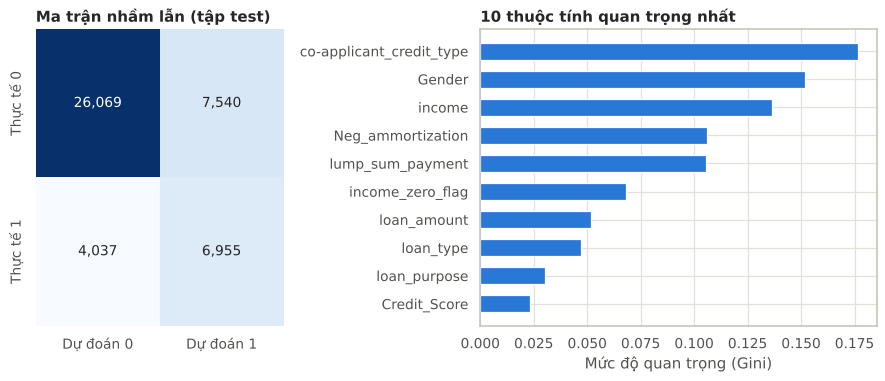

In [28]:
# ===== 3.11c. Ma trận nhầm lẫn và mức độ quan trọng của thuộc tính (Random Forest, kịch bản B) =====
pipe, pred, y_te = fitted_b["Random Forest"]
cm = confusion_matrix(y_te, pred)
print("Ma trận nhầm lẫn [hàng = thực tế 0/1, cột = dự đoán 0/1]:\n", cm)

names = pipe.named_steps["pre"].get_feature_names_out()
imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names)
# Gộp các cột One Hot và cột cờ thiếu về thuộc tính gốc
def base_name(n):
    n = n.split("__", 1)[1]
    n = n.replace("missingindicator_", "")
    for c in sorted(NUM_B + CAT_B, key=len, reverse=True):   # tên dài trước để không nhầm income_zero_flag với income
        if n == c or n.startswith(c + "_"):
            return c
    return n
imp_g = imp.groupby(imp.index.map(base_name)).sum().sort_values()
display(imp_g.sort_values(ascending=False).round(3).to_frame("muc_do_quan_trong"))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), gridspec_kw={"width_ratios": [1, 1.6]})
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=axes[0], annot_kws={"fontsize": 11},
            xticklabels=["Dự đoán 0", "Dự đoán 1"], yticklabels=["Thực tế 0", "Thực tế 1"])
axes[0].set_title("Ma trận nhầm lẫn (tập test)", loc="left", fontweight="bold")
top = imp_g.tail(10)
axes[1].barh(top.index, top.values, color=BLUE, height=0.6)
axes[1].set_xlabel("Mức độ quan trọng (Gini)")
axes[1].set_title("10 thuộc tính quan trọng nhất", loc="left", fontweight="bold")
save_fig("fig14_model_B")

## GIAI ĐOẠN 4: ĐÁNH GIÁ TÁC ĐỘNG VÀ KHUYẾN NGHỊ
Phần diễn giải, khuyến nghị và hạn chế của dữ liệu nằm trong báo cáo PDF. Ô dưới đây in ra các con số chính được dùng trong báo cáo.

In [29]:
# ===== 4.1. Đánh giá tác động: mô phỏng hai quy tắc sàng lọc trên các hồ sơ có đủ LTV và DTI =====
sub = df.dropna(subset=["LTV", "dtir1"])
rules = {
    "Quy tắc 1: LTV > 100% hoặc DTI > 50%": (sub["LTV"] > 100) | (sub["dtir1"] > 50),
    "Quy tắc 2: Quy tắc 1 + trả gộp cuối kỳ hoặc trả gốc âm": (sub["LTV"] > 100) | (sub["dtir1"] > 50)
        | sub["lump_sum_payment"].eq("lpsm") | sub["Neg_ammortization"].eq("neg_amm"),
}
rows = []
for name, flag in rules.items():
    rows.append({"quy_tac": name,
                 "ho_so_bi_gan_co_%": flag.mean() * 100,
                 "vo_no_nhom_gan_co_%": sub.loc[flag, "Status"].mean() * 100,
                 "vo_no_nhom_con_lai_%": sub.loc[~flag, "Status"].mean() * 100,
                 "ty_le_khoan_vo_no_bat_duoc_%": sub.loc[flag, "Status"].sum() / sub["Status"].sum() * 100})
print(f"Tập đánh giá: {len(sub):,} hồ sơ, tỷ lệ vỡ nợ {sub['Status'].mean():.1%}")
pd.DataFrame(rows).set_index("quy_tac").round(1)

Tập đánh giá: 124,547 hồ sơ, tỷ lệ vỡ nợ 16.3%


,ho_so_bi_gan_co_%,vo_no_nhom_gan_co_%,vo_no_nhom_con_lai_%,ty_le_khoan_vo_no_bat_duoc_%
quy_tac,,,,
Quy tắc 1: LTV > 100% hoặc DTI > 50%,7.9,45.9,13.8,22.1
Quy tắc 2: Quy tắc 1 + trả gộp cuối kỳ hoặc trả gốc âm,18.0,38.9,11.4,42.9


In [30]:
# ===== 4. Các con số chính dùng trong báo cáo =====
key = {
    "Số khoản vay": len(df),
    "Tỷ lệ vỡ nợ chung": f"{OVERALL:.2%}",
    "Vỡ nợ khi LTV > 100%": f"{df.loc[df.LTV > 100, 'Status'].mean():.1%}",
    "Vỡ nợ khi DTI > 50%": f"{df.loc[df.dtir1 > 50, 'Status'].mean():.1%}",
    "Vỡ nợ khi trả gộp cuối kỳ": f"{df.loc[df.lump_sum_payment == 'lpsm', 'Status'].mean():.1%}",
    "Vỡ nợ khi trả gốc âm": f"{df.loc[df.Neg_ammortization == 'neg_amm', 'Status'].mean():.1%}",
    "Vỡ nợ khi thiếu lãi suất": f"{df.loc[df.rate_of_interest.isna(), 'Status'].mean():.1%}",
    "AUC tốt nhất kịch bản B": f"{res_b['AUC'].max():.3f}",
}
pd.Series(key).to_frame("gia_tri")

,gia_tri
Số khoản vay,148670
Tỷ lệ vỡ nợ chung,24.64%
Vỡ nợ khi LTV > 100%,65.1%
Vỡ nợ khi DTI > 50%,42.7%
Vỡ nợ khi trả gộp cuối kỳ,77.7%
Vỡ nợ khi trả gốc âm,44.6%
Vỡ nợ khi thiếu lãi suất,100.0%
AUC tốt nhất kịch bản B,0.771
